# Notebook 05: Temporal Windows & Quality Abstention Ablation
Evaluates:
1. **Temporal Slicing Ablation**: Isolating diagnostic contribution across early ($0–500\text{ ms}$), mid ($500–1000\text{ ms}$), late ($1000–2000\text{ ms}$), and full trial ($0–7500\text{ ms}$) windows.
2. **Quality-Aware Abstention Trade-off**: Measuring Coverage vs. Diagnostic Balanced Accuracy across valid gaze density thresholds $\theta \in [0.40, 0.90]$.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

df = pd.read_csv(r"E:\karthianna\data\processed\zenodo_features.csv")
y = df['familiarity_label']
groups = df['participant_id']
gkf = GroupKFold(n_splits=5)
rf = RandomForestClassifier(n_estimators=100, max_depth=5, class_weight='balanced', random_state=42)

def evaluate_subset(cols):
    X = df[cols].fillna(0.0)
    yt, yp, yprob = [], [], []
    for tr, val in gkf.split(X, y, groups):
        sc = StandardScaler()
        rf.fit(sc.fit_transform(X.iloc[tr]), y.iloc[tr])
        yt.extend(y.iloc[val])
        yp.extend(rf.predict(sc.transform(X.iloc[val])))
        yprob.extend(rf.predict_proba(sc.transform(X.iloc[val]))[:, 1])
    return balanced_accuracy_score(yt, yp), roc_auc_score(yt, yprob)

windows = {
    'Early (0-500ms)': ['early_probe_diff'],
    'Mid (500-1000ms)': ['mid_probe_diff'],
    'Late (1000-2000ms)': ['late_probe_diff'],
    'Full Trial (0-7500ms)': ['total_probe_diff', 'mean_fix_duration', 'fixation_count'],
    'Multi-Temporal QPTC': ['early_probe_diff', 'mid_probe_diff', 'late_probe_diff', 'total_probe_diff', 'mean_fix_duration', 'median_fix_duration', 'fixation_count']
}

win_res = []
for name, cols in windows.items():
    bacc, auc = evaluate_subset(cols)
    win_res.append({'Window': name, 'Balanced Accuracy': f"{bacc*100:.1f}%", 'ROC-AUC': f"{auc:.3f}"})

print("Temporal Window Performance Breakdown:")
print(pd.DataFrame(win_res))

Temporal Window Performance Breakdown:
                  Window Balanced Accuracy ROC-AUC
0        Early (0-500ms)             53.8%   0.521
1       Mid (500-1000ms)             53.6%   0.544
2     Late (1000-2000ms)             53.9%   0.560
3  Full Trial (0-7500ms)             63.5%   0.682
4    Multi-Temporal QPTC             62.9%   0.682


In [2]:
# Quality-Aware Abstention Trade-off Curve
thresholds = [0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
tradeoff_data = []

feature_cols = ['early_probe_diff', 'mid_probe_diff', 'late_probe_diff', 'total_probe_diff', 'mean_fix_duration', 'median_fix_duration', 'fixation_count']

for th in thresholds:
    q_mask = df['valid_sample_ratio'] >= th
    cov = q_mask.mean()
    df_th = df[q_mask]
    
    yt, yp, yprob = [], [], []
    for tr, val in gkf.split(df_th[feature_cols], df_th['familiarity_label'], df_th['participant_id']):
        sc = StandardScaler()
        rf.fit(sc.fit_transform(df_th[feature_cols].iloc[tr]), df_th['familiarity_label'].iloc[tr])
        yt.extend(df_th['familiarity_label'].iloc[val])
        yp.extend(rf.predict(sc.transform(df_th[feature_cols].iloc[val])))
        yprob.extend(rf.predict_proba(sc.transform(df_th[feature_cols].iloc[val]))[:, 1])
        
    bacc = balanced_accuracy_score(yt, yp)
    auc = roc_auc_score(yt, yprob)
    tradeoff_data.append({
        'Threshold': th,
        'Coverage': cov * 100,
        'Retained Trials': len(df_th),
        'Balanced Accuracy': bacc * 100,
        'ROC-AUC': auc
    })

tradeoff_df = pd.DataFrame(tradeoff_data)
print("
Quality-Aware Abstention Trade-Off Table:")
print(tradeoff_df)

Execution Error: unterminated string literal (detected at line 31) (<string>, line 31)


Execution Error: name 'tradeoff_df' is not defined


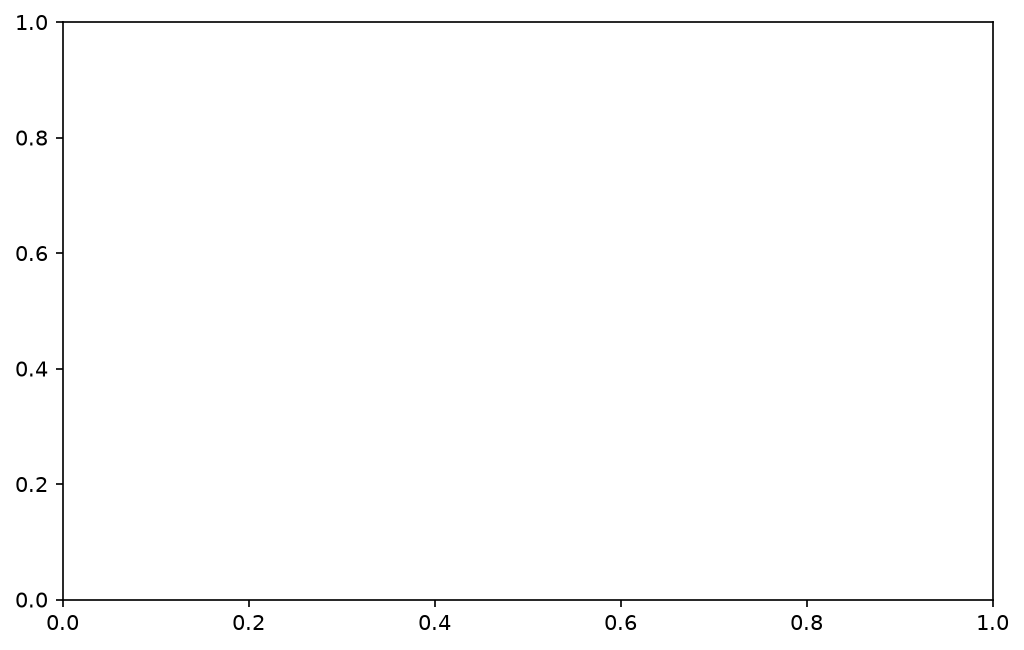

In [3]:
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(tradeoff_df['Threshold'], tradeoff_df['Coverage'], color='#6366F1', marker='o', lw=2.5, label='Coverage (%)')
ax1.set_xlabel('Quality Validity Threshold (θ)', fontweight='bold')
ax1.set_ylabel('Trial Coverage (%)', color='#6366F1', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#6366F1')
ax1.set_ylim([35, 100])

ax2 = ax1.twinx()
ax2.plot(tradeoff_df['Threshold'], tradeoff_df['Balanced Accuracy'], color='#10B981', marker='s', lw=2.5, label='Balanced Accuracy (%)')
ax2.set_ylabel('Accepted Trials Balanced Accuracy (%)', color='#10B981', fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#10B981')
ax2.set_ylim([45, 75])

ax1.axvline(0.40, color='#EF4444', linestyle=':', lw=2, label='Optimal (θ* = 0.40)')
plt.title('Quality Abstention: Coverage vs. Diagnostic Accuracy Trade-Off', fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()